# Train Test Splits, Cross Validation, and Linear Regression



# Learning Objectives

- Explicarea diferenței dintre supraadaptarea și subadaptarea unui model
- Descrieți compromisurile bias-varianță
- Găsiți împărțirea optimă a seturilor de date de instruire și de testare, validarea încrucișată și complexitatea modelului în funcție de eroare
- Aplicarea unui model de regresie liniară pentru învățarea supravegheată


## Introduction

Vom lucra cu un set de date bazat pe [prețurile locuințelor în Ames, Iowa] (https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Acesta a fost compilat pentru uz educațional pentru a fi o alternativă modernizată și extinsă la binecunoscutul set de date Boston Housing. Această versiune a setului de date a fost completată cu unele valori lipsă pentru comoditate.

Există un număr extins de caracteristici, astfel încât acestea au fost descrise în tabelul de mai jos.

### Predictor

* SalePrice: Prețul de vânzare al proprietății în dolari. 


### Features

<table>
  <tbody>    
    <tr valign="top">
      <td valign="top">
        <ul>
          <li>MoSold: Month Sold</li>
          <li>YrSold: Year Sold</li><br>
          
          <li>SaleType: Type of sale</li>
          <li>SaleCondition: Condition of sale</li><br>

          <li>MSSubClass: The building class</li>
          <li>MSZoning: The general zoning classification</li><br>

          <li>Neighborhood: Physical locations within Ames city limits</li>
          <li>Street: Type of road access</li>
          <li>Alley: Type of alley access</li><br>

          <li>LotArea: Lot size in square feet</li>
          <li>LotConfig: Lot configuration</li>
          <li>LotFrontage: Linear feet of street connected to property</li>
          <li>LotShape: General shape of property</li><br>

          <li>LandSlope: Slope of property</li>
          <li>LandContour: Flatness of the property</li><br>

          <li>YearBuilt: Original construction date</li>
          <li>YearRemodAdd: Remodel date</li>
          <li>OverallQual: Overall material and finish quality</li>
          <li>OverallCond: Overall condition rating</li><br>

          <li>Utilities: Type of utilities available</li>
          <li>Foundation: Type of foundation</li>
          <li>Functional: Home functionality rating</li><br>

          <li>BldgType: Type of dwelling</li>
          <li>HouseStyle: Style of dwelling</li><br>
          
          <li>1stFlrSF: First Floor square feet</li>
          <li>2ndFlrSF: Second floor square feet</li>
          <li>LowQualFinSF: Low quality finished square feet (all floors)</li>
          <li>GrLivArea: Above grade (ground) living area square feet</li>
          <li>TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)</li><br>

          <li>Condition1: Proximity to main road or railroad</li>
          <li>Condition2: Proximity to main road or railroad (if a second is present)</li><br>
          
          <li>RoofStyle: Type of roof</li>
          <li>RoofMatl: Roof material</li><br>

          <li>ExterQual: Exterior material quality</li>
          <li>ExterCond: Present condition of the material on the exterior</li>
          <li>Exterior1st: Exterior covering on house</li>
          <li>Exterior2nd: Exterior covering on house (if more than one material)</li><br><br>
          
        </ul>
      </td>
      
      <td valign="top">
        <ul>
          <li>MasVnrType: Masonry veneer type</li>
          <li>MasVnrArea: Masonry veneer area in square feet</li><br>
          
          <li>WoodDeckSF: Wood deck area in square feet</li>
          <li>OpenPorchSF: Open porch area in square feet</li>
          <li>EnclosedPorch: Enclosed porch area in square feet</li>
          <li>3SsnPorch: Three season porch area in square feet</li>
          <li>ScreenPorch: Screen porch area in square feet</li><br>

          <li>PoolArea: Pool area in square feet</li>
          <li>PoolQC: Pool quality</li>
          <li>Fence: Fence quality</li>
          <li>PavedDrive: Paved driveway</li><br>

          <li>GarageType: Garage location</li>
          <li>GarageYrBlt: Year garage was built</li>
          <li>GarageFinish: Interior finish of the garage</li>
          <li>GarageCars: Size of garage in car capacity</li>
          <li>GarageArea: Size of garage in square feet</li>
          <li>GarageQual: Garage quality</li>
          <li>GarageCond: Garage condition</li><br>

          <li>Heating: Type of heating</li>
          <li>HeatingQC: Heating quality and condition</li>
          <li>CentralAir: Central air conditioning</li>
          <li>Electrical: Electrical system</li><br>
          
          <li>FullBath: Full bathrooms above grade</li>
          <li>HalfBath: Half baths above grade</li><br>
          
          <li>BedroomAbvGr: Number of bedrooms above basement level</li><br>
          
          <li>KitchenAbvGr: Number of kitchens</li>
          <li>KitchenQual: Kitchen quality</li><br>
          
          <li>Fireplaces: Number of fireplaces</li>
          <li>FireplaceQu: Fireplace quality</li><br>
          
          <li>MiscFeature: Miscellaneous feature not covered in other categories</li>
          <li>MiscVal: Value of miscellaneous feature</li><br>
          
          <li>BsmtQual: Height of the basement</li>
          <li>BsmtCond: General condition of the basement</li>
          <li>BsmtExposure: Walkout or garden level basement walls</li>
          <li>BsmtFinType1: Quality of basement finished area</li>
          <li>BsmtFinSF1: Type 1 finished square feet</li>
          <li>BsmtFinType2: Quality of second finished area (if present)</li>
          <li>BsmtFinSF2: Type 2 finished square feet</li>
          <li>BsmtUnfSF: Unfinished square feet of basement area</li>
          <li>BsmtFullBath: Basement full bathrooms</li>
          <li>BsmtHalfBath: Basement half bathrooms</li>
          <li>TotalBsmtSF: Total square feet of basement area</li>
        </ul>
      </td>
    </tr>
    
  </tbody>
</table>


### Pregătire (Google Colab)
Dacă fișierul `Ames_Housing_Sales.csv` nu există în sesiune, se deschide fereastra de încărcare.

In [1]:
import os
FILES = ['Ames_Housing_Sales.csv']
missing = [f for f in FILES if not os.path.exists(f)]
if missing:
    print('Încărcați fișierele:', missing)
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

RANDOM_STATE = 42

## Question 1

* Importați datele utilizând Pandas și examinați forma. Există 79 de coloane de caracteristici plus predictorul, prețul de vânzare (`SalePrice`). 
* Există trei tipuri diferite: numere întregi (`int64`), numere float (`float64`) și șiruri de caractere (`object`, categoricals). Examinați câte există din fiecare tip de date. 

In [2]:
# În fișier, valoarea 'None' înseamnă „lipsește” (ex. Alley = None -> nu există alee).
# Pandas ar transforma implicit textul 'None' în NaN, de aceea îl păstrăm ca o categorie separată.
data = pd.read_csv('Ames_Housing_Sales.csv', keep_default_na=False, na_values=[''])

print('Forma datelor:', data.shape)
print('Valori lipsă:', data.isnull().sum().sum())
data.head()

Forma datelor: (1379, 80)
Valori lipsă: 0


,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,...,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,None,3,1Fam,TA,No,706.0,0.0,...,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,None,3,1Fam,TA,Gd,978.0,0.0,...,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,None,3,1Fam,TA,Mn,486.0,0.0,...,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,None,3,1Fam,Gd,No,216.0,0.0,...,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,None,4,1Fam,TA,Av,655.0,0.0,...,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0


In [3]:
# Coloanele text pot apărea ca 'object' (pandas 2) sau 'str' (pandas 3) – le tratăm la fel
is_num = data.dtypes.apply(pd.api.types.is_numeric_dtype)
cat_cols = data.columns[~is_num].tolist()
num_cols = data.columns[is_num].tolist()

types = data.dtypes.astype(str).replace({'str': 'object', 'string': 'object'})
print('Numărul de coloane pe tip de date:')
print(types.value_counts())
print(f'\nCaracteristici: {data.shape[1] - 1} + predictorul SalePrice')

Numărul de coloane pe tip de date:
object     43
float64    21
int64      16
Name: count, dtype: int64

Caracteristici: 79 + predictorul SalePrice


**Rezultat:** 1379 rânduri × 80 coloane (79 caracteristici + `SalePrice`). Tipuri: **43 `object`** (șiruri/categorii), **21 `float64`**, **16 `int64`**.

*Notă:* în fișier valoarea text `None` înseamnă „nu există” (fără alee, fără piscină, fără subsol…). Pandas o transformă implicit în `NaN`, de aceea am citit fișierul cu `keep_default_na=False` – astfel `None` rămâne o categorie validă și nu există valori lipsă.

## Question 2

După cum s-a discutat în prelegere, o provocare semnificativă, în special atunci când este vorba de date care au mai multe coloane, este să se asigure că fiecare coloană este codificată corect. 

Acest lucru este valabil în special în cazul coloanelor de date care sunt categorice ordonate (ordonate) vs. categorice neordonate. Categoriile neordonate ar trebui să fie codificate o singură dată, însă acest lucru poate crește semnificativ numărul de caracteristici și creează caracteristici care sunt foarte corelate între ele.

Determinați câte caracteristici totale ar fi prezente, în raport cu ceea ce există în prezent, dacă toate caracteristicile șirurilor (obiectelor) sunt codificate o singură dată. Reamintim că numărul total de coloane cu codificare one-hot este `n-1`, unde `n` este numărul de categorii.

In [4]:
# Pentru fiecare coloană categorială: n categorii -> n-1 coloane one-hot
num_ohe = (data[cat_cols].nunique() - 1)
print('Coloane one-hot pe fiecare caracteristică categorială (primele 10):')
print(num_ohe.sort_values(ascending=False).head(10))

n_features_now = data.shape[1] - 1                      # fără SalePrice
n_features_ohe = n_features_now - len(cat_cols) + num_ohe.sum()
print(f'\nColoane categoriale: {len(cat_cols)}, vor fi înlocuite cu {num_ohe.sum()} coloane one-hot')
print(f'Caracteristici acum: {n_features_now}  ->  după one-hot: {n_features_ohe} '
      f'(de {n_features_ohe / n_features_now:.1f} ori mai multe)')

Coloane one-hot pe fiecare caracteristică categorială (primele 10):
Neighborhood    24
Exterior2nd     15
Exterior1st     13
SaleType         8
Condition1       8
RoofMatl         7
HouseStyle       7
Condition2       7
Functional       6
BsmtFinType2     6
dtype: int64

Coloane categoriale: 43, vor fi înlocuite cu 215 coloane one-hot
Caracteristici acum: 79  ->  după one-hot: 251 (de 3.2 ori mai multe)


## Question 3

Să creăm un nou set de date în care toate caracteristicile categorice de mai sus vor fi codificate o singură dată. Putem ajusta aceste date și să vedem cum afectează rezultatele.

* Am folosit metoda `.copy()` a cadrului de date pentru a crea o copie complet separată a cadrului de date pentru codificarea one-hot
* Pe acest nou cadru de date, codificați o singură dată fiecare dintre coloanele corespunzătoare și adăugați-o înapoi la cadrul de date. Asigurați-vă că renunțați la coloana originală.
* Pentru datele care nu sunt codificate o singură dată, renunțați la coloanele care sunt șiruri categoriale.

Pentru primul pas, codificarea numerică a categoriilor de șiruri, se poate utiliza `LabelEncoder` sau `DictVectorizer` din Scikit-learn. Cu toate acestea, primul este probabil mai ușor, deoarece nu necesită specificarea unei valori numerice pentru fiecare categorie, iar noi vom codifica oricum toate valorile numerice printr-o singură dată. (Vă puteți gândi la un moment în care `DictVectorizer` ar putea fi preferat?)

In [5]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Copie separată pentru codificarea one-hot
data_ohc = data.copy()

le = LabelEncoder()
ohc = OneHotEncoder(drop='first')              # n-1 coloane pentru n categorii

for col in cat_cols:
    # 1) codificare numerică a șirurilor
    dat = le.fit_transform(data_ohc[col].astype(str)).astype(int)
    data_ohc = data_ohc.drop(col, axis=1)      # renunțăm la coloana originală

    # 2) codificare one-hot
    new_dat = ohc.fit_transform(dat.reshape(-1, 1)).toarray()
    n_cols = new_dat.shape[1]
    col_names = ['_'.join([col, str(x)]) for x in le.classes_[1:]]   # prima categorie = referință
    new_df = pd.DataFrame(new_dat, index=data_ohc.index, columns=col_names)

    # 3) adăugăm înapoi la cadrul de date
    data_ohc = pd.concat([data_ohc, new_df], axis=1)

# Setul fără one-hot: eliminăm pur și simplu coloanele categoriale
data_num = data.drop(columns=cat_cols)

print('Date fără one-hot :', data_num.shape)
print('Date cu one-hot   :', data_ohc.shape)
print('Diferența de coloane:', data_ohc.shape[1] - data_num.shape[1])

Date fără one-hot : (1379, 37)
Date cu one-hot   : (1379, 252)
Diferența de coloane: 215


**Când este preferat `DictVectorizer`?** Când datele vin ca listă de dicționare (ex. JSON, înregistrări cu câmpuri diferite/lipsă), când avem amestec de caracteristici numerice și text într-un singur pas (numericele rămân neschimbate, textul devine one-hot automat) sau când avem foarte multe categorii – returnează direct o matrice *sparse*, economisind memorie. Spre deosebire de `LabelEncoder`, nu este nevoie de doi pași (etichetă → one-hot).

## Question 4

* Creați împărțiri de instruire și de testare ale ambelor seturi de date. Pentru a vă asigura că datele sunt împărțite în același mod, utilizați același `random_state` în fiecare dintre cele două împărțiri.
* Pentru fiecare set de date, ajustați un model de regresie liniară de bază pe datele de antrenament. 
* Calculați eroarea pătratică medie pe seturile de antrenament și de testare pentru modelele respective. Care model produce o eroare mai mică pe datele de testare și de ce?

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

y_col = 'SalePrice'

# Date fără one-hot
X_data = data_num.drop(columns=y_col)
y_data = data_num[y_col]
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.3, random_state=RANDOM_STATE)

# Date cu one-hot – același random_state => aceleași rânduri în train/test
X_data_ohc = data_ohc.drop(columns=y_col)
y_data_ohc = data_ohc[y_col]
X_train_ohc, X_test_ohc, y_train_ohc, y_test_ohc = train_test_split(X_data_ohc, y_data_ohc, test_size=0.3, random_state=RANDOM_STATE)

# Verificăm că împărțirea este identică
print('Aceiași indecși în train:', (X_train.index == X_train_ohc.index).all())

LR = LinearRegression()
error_df = []

LR.fit(X_train, y_train)
error_df.append(pd.Series({'train': mean_squared_error(y_train, LR.predict(X_train)),
                           'test':  mean_squared_error(y_test,  LR.predict(X_test))}, name='fără one-hot'))

LR.fit(X_train_ohc, y_train_ohc)
error_df.append(pd.Series({'train': mean_squared_error(y_train_ohc, LR.predict(X_train_ohc)),
                           'test':  mean_squared_error(y_test_ohc,  LR.predict(X_test_ohc))}, name='cu one-hot'))

error_df = pd.concat(error_df, axis=1)
pd.options.display.float_format = '{:,.3e}'.format
display(error_df)
print('RMSE ($):'); display(np.sqrt(error_df).style.format('{:,.0f}'))

Aceiași indecși în train: True


,fără one-hot,cu one-hot
train,1.132e+09,3.432e+08
test,1.372e+09,2.698e+09


RMSE ($):


,fără one-hot,cu one-hot
train,"33,638","18,526"
test,"37,043","51,947"


**Rezultat (RMSE):**

| | train | test |
|---|---|---|
| fără one-hot (36 caracteristici) | ~33 600 $ | **~37 000 $** |
| cu one-hot (251 caracteristici) | ~18 500 $ | ~51 900 $ |

Modelul **fără one-hot** dă o eroare mai mică pe test. Modelul cu one-hot are de ~7 ori mai multe caracteristici (251) la doar 965 de rânduri de antrenare: eroarea pe train scade mult (se potrivește foarte bine datelor), dar pe test crește – este **supraadaptare (overfitting)**, adică varianță mare. Multe coloane dummy sunt rare (câteva case cu o anumită categorie) și foarte corelate, deci coeficienții lor sunt instabili. Modelul fără one-hot este mai simplu (bias puțin mai mare, varianță mult mai mică) și generalizează mai bine – compromisul bias–varianță.

Rețineți că valorile erorilor privind datele codificate printr-o singură lovitură sunt foarte diferite pentru datele de formare și cele de testare. În special, erorile privind datele de testare sunt mult mai mari. Pe baza lecției, acest lucru se datorează faptului că modelul codificat o singură dată se potrivește prea bine datelor. Vom învăța cum să rezolvăm astfel de probleme în lecția următoare.

## Question 5

Pentru fiecare dintre seturile de date (codificate la cald și necodificate):

* Scalați toate valorile codificate non-hot utilizând una dintre următoarele metode: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`.
* Comparați eroarea calculată pe seturile de testare

Asigurați-vă că calculați oblicitatea (pentru a decide dacă trebuie efectuată o transformare) și ajustați scalerul pe *NUMai* datele de formare, dar apoi aplicați-l identic atât pe datele de formare, cât și pe cele de testare.

Cele mai asimetrice caracteristici (skew > 0.75):


,skew
MiscVal,26.915
PoolArea,15.778
LotArea,11.502
LowQualFinSF,11.211
3SsnPorch,10.151
KitchenAbvGr,5.498
ScreenPorch,4.600
BsmtFinSF2,4.466
BsmtHalfBath,3.882
EnclosedPorch,3.218


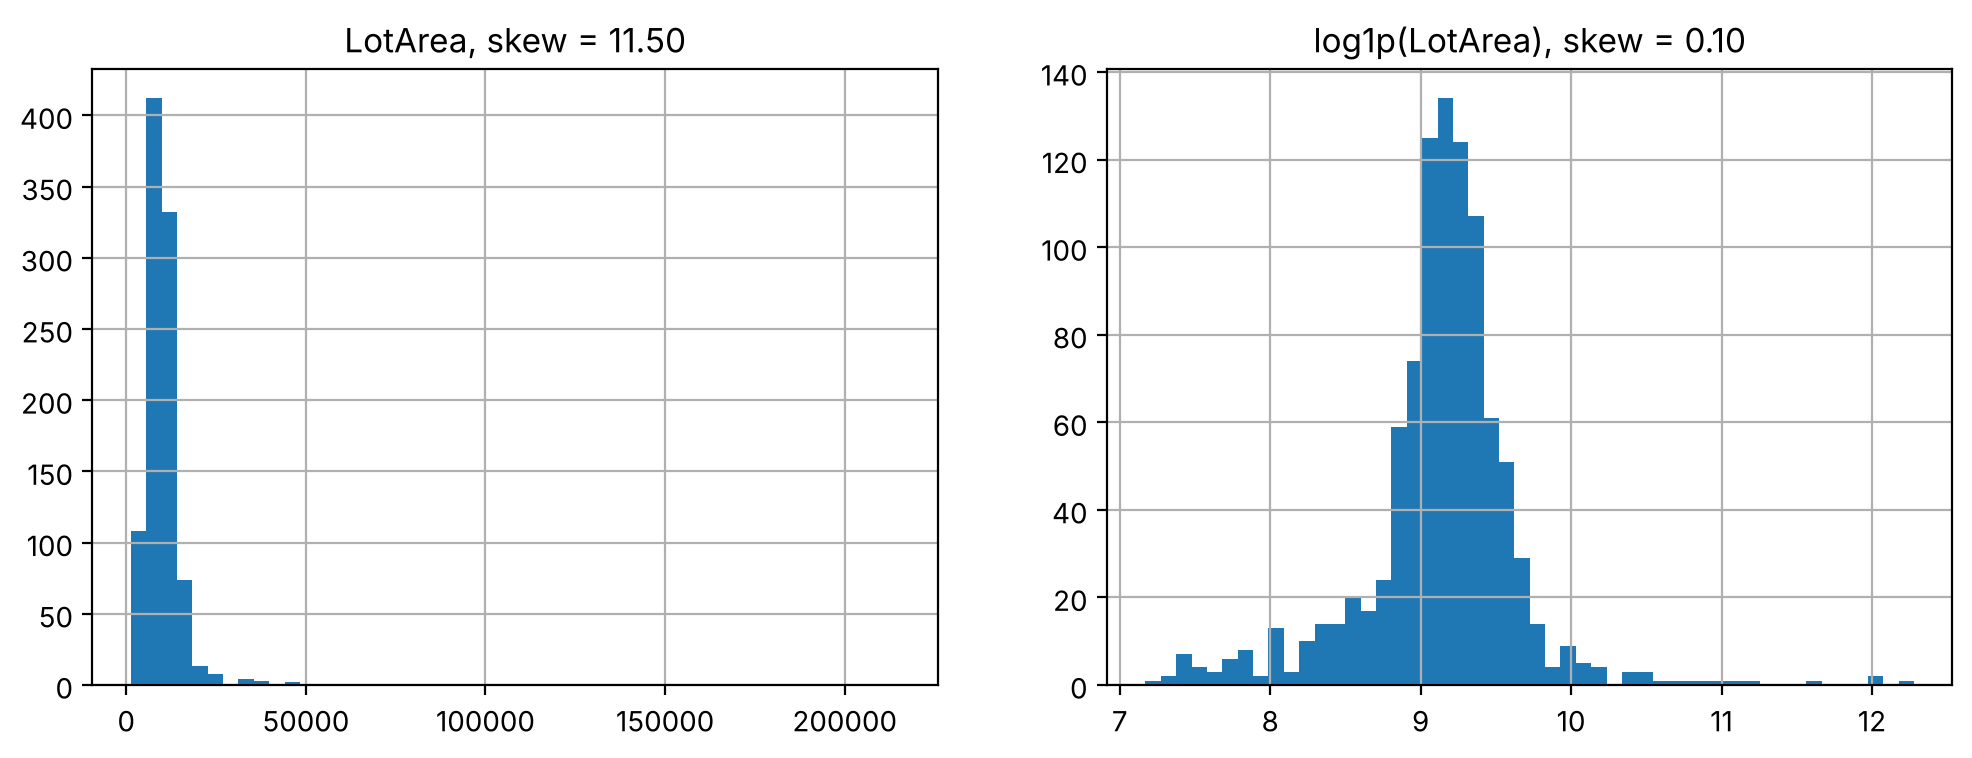

In [7]:
# 1) Oblicitatea (skewness) caracteristicilor numerice – calculată DOAR pe train
float_cols = [col for col in X_train.columns]          # toate coloanele numerice (non one-hot)
skew = X_train[float_cols].skew().sort_values(ascending=False)
pd.options.display.float_format = '{:,.3f}'.format
print('Cele mai asimetrice caracteristici (skew > 0.75):')
display(skew[skew.abs() > 0.75].to_frame('skew'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
X_train['LotArea'].hist(bins=50, ax=ax[0]); ax[0].set_title(f'LotArea, skew = {skew["LotArea"]:.2f}')
np.log1p(X_train['LotArea']).hist(bins=50, ax=ax[1]); ax[1].set_title(f'log1p(LotArea), skew = {np.log1p(X_train["LotArea"]).skew():.2f}')
plt.show()

In [8]:
# 2) Transformare logaritmică pentru coloanele cu skew > 0.75 (lista determinată pe train),
#    aplicată identic pe train și test
skew_cols = skew[skew.abs() > 0.75].index.tolist()

def log_transform(df):
    df = df.copy()
    df[skew_cols] = np.log1p(df[skew_cols].clip(lower=0))
    return df

X_train_log, X_test_log = log_transform(X_train), log_transform(X_test)
X_train_ohc_log, X_test_ohc_log = log_transform(X_train_ohc), log_transform(X_test_ohc)
print('Coloane transformate:', len(skew_cols))

Coloane transformate: 23


In [9]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler

scalers = {'standard': StandardScaler(), 'minmax': MinMaxScaler(), 'maxabs': MaxAbsScaler()}
non_ohe_cols = X_train.columns.tolist()     # se scalează doar coloanele NON one-hot

def evaluate(Xtr, Xte, ytr, yte, scaler):
    Xtr, Xte = Xtr.copy(), Xte.copy()
    if scaler is not None:
        scaler.fit(Xtr[non_ohe_cols])                        # fit DOAR pe train
        Xtr[non_ohe_cols] = scaler.transform(Xtr[non_ohe_cols])
        Xte[non_ohe_cols] = scaler.transform(Xte[non_ohe_cols])   # aceeași transformare pe test
    lr = LinearRegression().fit(Xtr, ytr)
    return mean_squared_error(ytr, lr.predict(Xtr)), mean_squared_error(yte, lr.predict(Xte))

rows = {}
for log_name, (a, b, c_, d) in {'fără log': (X_train, X_test, X_train_ohc, X_test_ohc),
                                'cu log':   (X_train_log, X_test_log, X_train_ohc_log, X_test_ohc_log)}.items():
    for sc_name, sc in [('fără scalare', None)] + list(scalers.items()):
        tr, te = evaluate(a, b, y_train, y_test, sc)
        tr_o, te_o = evaluate(c_, d, y_train_ohc, y_test_ohc, sc)
        rows[(log_name, sc_name)] = {'RMSE test (fără one-hot)': np.sqrt(te), 'RMSE test (cu one-hot)': np.sqrt(te_o),
                                     'RMSE train (cu one-hot)': np.sqrt(tr_o)}

res = pd.DataFrame(rows).T
display(res.style.format('{:,.0f}'))

**Concluzii.**

- Multe caracteristici sunt puternic asimetrice (skew > 0.75: `MiscVal`, `PoolArea`, `LotArea`…), de aceea am aplicat `log1p` – lista coloanelor s-a determinat **doar pe train**, iar scalerul s-a ajustat (`fit`) doar pe train și s-a aplicat (`transform`) identic pe train și test.
- **Pentru datele fără one-hot** scalarea nu schimbă nimic (RMSE test ~37 000 $ pentru toate scalerele): regresia liniară obișnuită (OLS) este invariantă la transformări liniare ale caracteristicilor – coeficienții se ajustează invers proporțional, iar predicțiile rămân aceleași. Transformarea logaritmică ajută puțin (37 043 → 36 389 $), deoarece schimbă forma relației (neliniar).
- **Pentru datele cu one-hot** eroarea pe test este mare și instabilă (52 000–79 000 $) – matricea caracteristicilor este aproape singulară (coloane rare și coliniare), deci mici schimbări numerice (scalarea, logaritmul) schimbă mult soluția. Pe train eroarea rămâne mică (~18 000–20 000 $) – supraadaptare clară.
- Scalarea devine importantă pentru modelele cu **regularizare** (Ridge/Lasso) și pentru **coborârea gradientului** – lecția următoare.

## Question 6

Reprezentați grafic previziunile față de realitate pentru unul dintre modele.

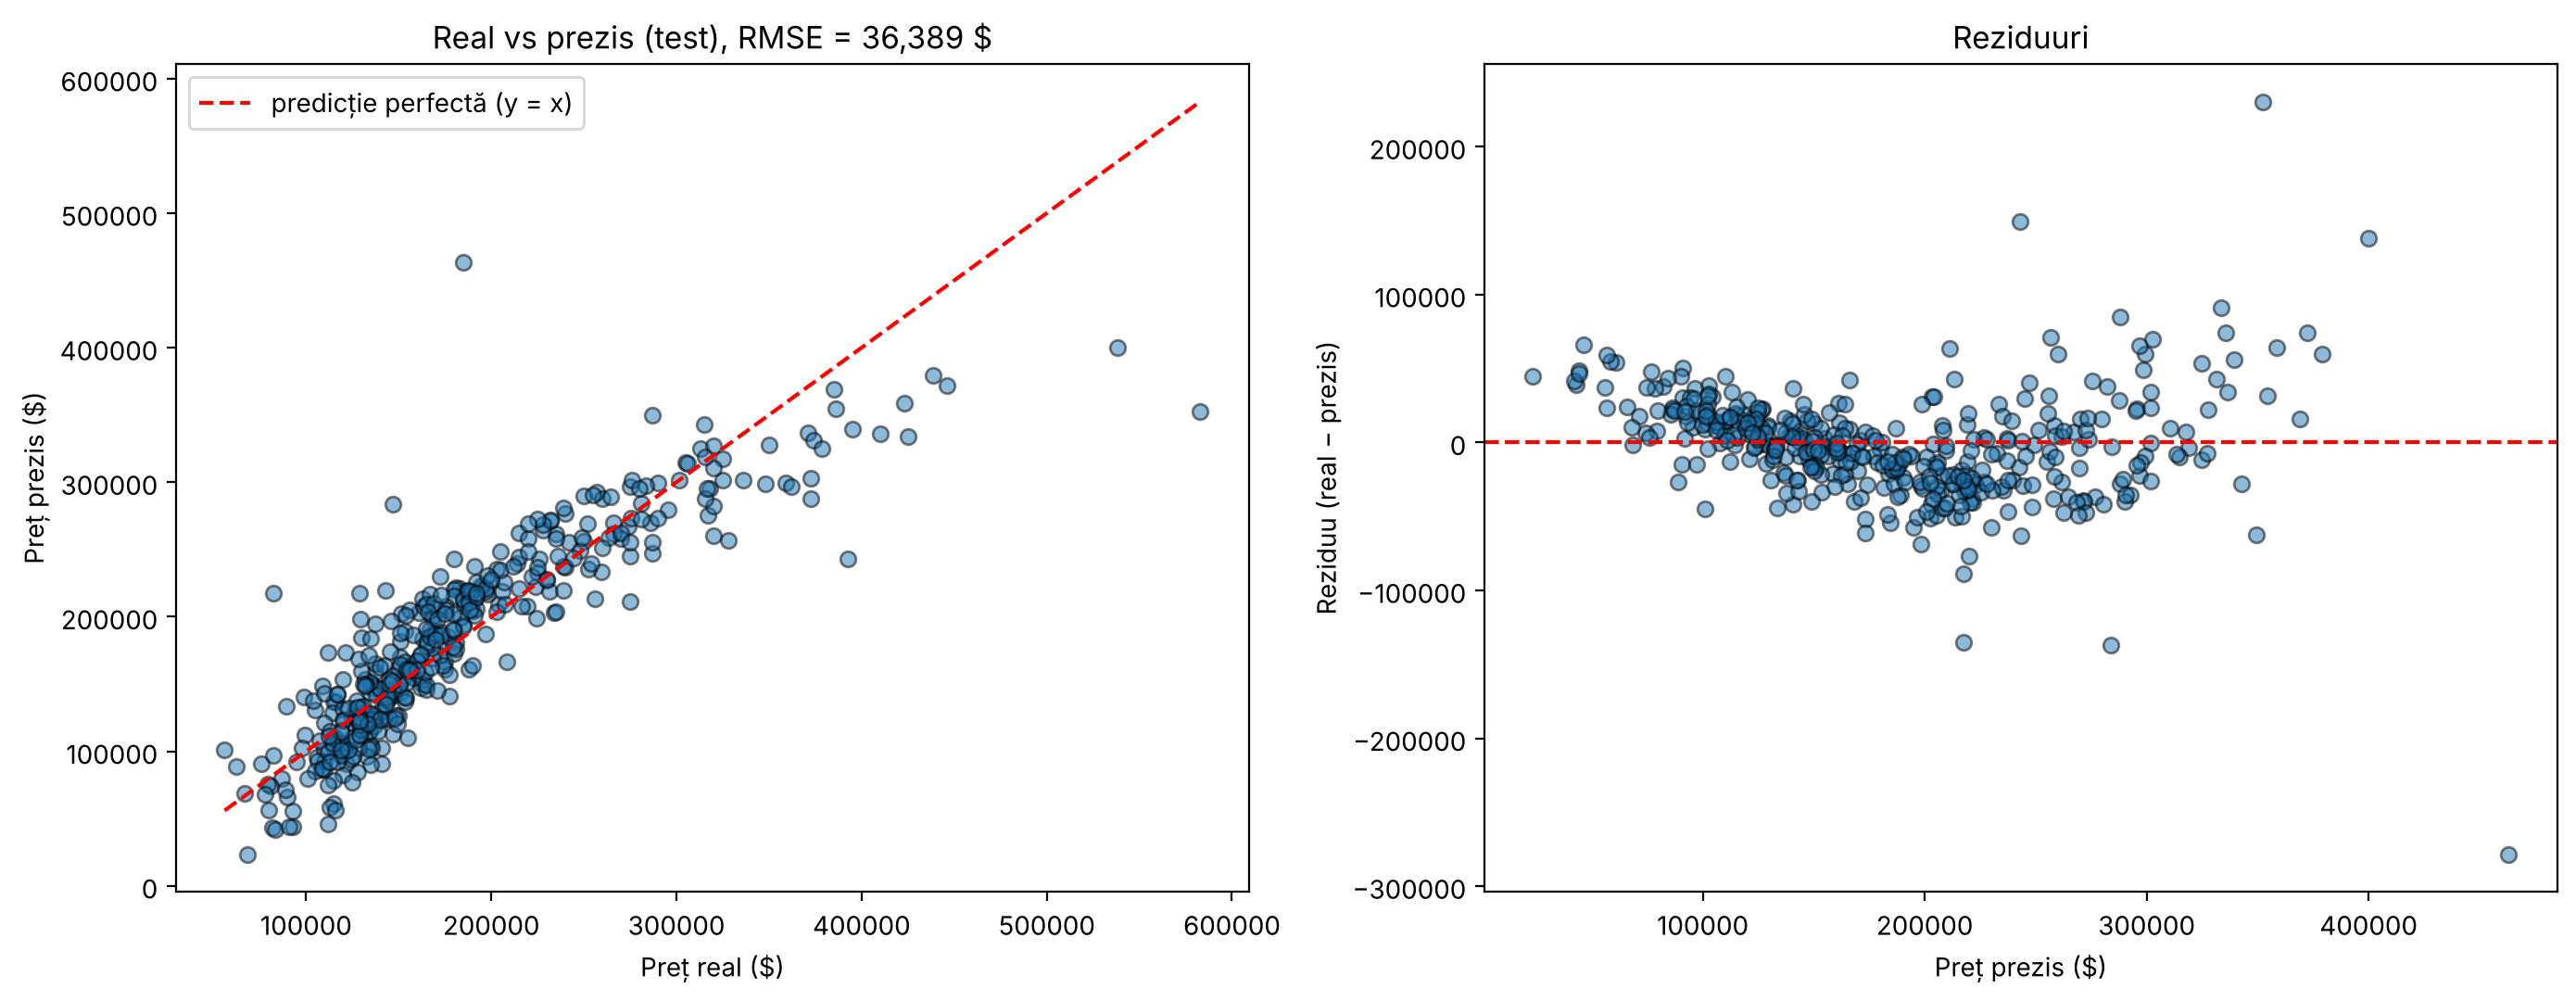

In [10]:
# Modelul fără one-hot, cu log-transform și StandardScaler
sc = StandardScaler().fit(X_train_log)
lr = LinearRegression().fit(sc.transform(X_train_log), y_train)
y_pred = lr.predict(sc.transform(X_test_log))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, 'r--', label='predicție perfectă (y = x)')
ax[0].set_xlabel('Preț real ($)'); ax[0].set_ylabel('Preț prezis ($)')
ax[0].set_title(f'Real vs prezis (test), RMSE = {np.sqrt(mean_squared_error(y_test, y_pred)):,.0f} $')
ax[0].legend(); ax[0].ticklabel_format(style='plain')

resid = y_test - y_pred
ax[1].scatter(y_pred, resid, alpha=0.5, edgecolor='k'); ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('Preț prezis ($)'); ax[1].set_ylabel('Reziduu (real − prezis)'); ax[1].set_title('Reziduuri')
ax[1].ticklabel_format(style='plain')
plt.tight_layout(); plt.show()

**Interpretare.** Punctele sunt grupate în jurul diagonalei, deci modelul surprinde bine tendința generală. Însă pentru casele scumpe (> 400 000 $) erorile cresc, iar reziduurile au formă de pâlnie (heteroscedasticitate) – prețul are o distribuție asimetrică. O îmbunătățire ar fi logaritmarea și a țintei `SalePrice` și folosirea regularizării.